# Online Shoppers Purchasing Intention — Full ML Research Notebook
### Decision Tree from Scratch (NumPy) vs. Scikit-learn

**Google Colab edition | Reproducing Parts 1–8 of our 2026 Mathematics for ML project**

This notebook reconstructs the work completed in VS Code and GitHub, in the approachable style of **Lab 1 — Regression from Scratch**. Run the cells from top to bottom (**Runtime → Run all**). The computation uses the original dataset, not fabricated sample observations.

**Research question:** Can online-shopping session characteristics predict whether a purchase occurs (`Revenue` = 1)?

**What is included:** EDA, feature selection, reproducible 60/20/20 split, one-hot encoding fitted to training categories, Gini mathematics, NumPy decision tree, checkpoints, scikit-learn comparison, model selection by validation F1, held-out final test, baseline, graphs, tables, interpretation, and reproducibility notes.

> **Exact-output requirement:** Upload the same `online_shoppers_intention.csv` used in your VS Code project (12,330 rows, original row order). Code, random seed (`42`), split logic, candidate thresholds, depth choices, and metrics reproduce the methods used in the chat. Scikit-learn results can vary slightly across library versions; the notebook prints recorded outcomes for comparison rather than silently replacing measured results.

## 0. Setup and data loading

This notebook runs in Google Colab without your Mac's `src/` directory. Your local dataset is ignored by Git, so it will **not** arrive automatically from GitHub. Upload the original CSV in the cell below. You can also place it in Colab's working directory before running the cell.

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# Printing the library versions
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

# Getting the original shopping dataset
filename = "online_shoppers_intention.csv"
if not os.path.exists(filename):
    from google.colab import files
    print("Please upload the original online_shoppers_intention.csv file")
    uploaded = files.upload()
    assert filename in uploaded, "Upload the file named online_shoppers_intention.csv"

data = pd.read_csv(filename)
print("Dataset loaded:", data.shape)
assert data.shape == (12330, 18), "This is not the expected original 12,330-row dataset"

NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Dataset loaded: (12330, 18)


### Dataset source and provenance

Dataset: **Online Shoppers Purchasing Intention Dataset**, publicly distributed on Kaggle: https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset

The same CSV and its **original row order** are important. We reproduce the exact NumPy permutation used in your local `src/split_data.py`. We do **not** download an alternate version or change the order of observations.

## 1. Exploratory data analysis (Part 1)

A supervised learning dataset has input variables $X$ and outcomes $y$. Before modeling we inspect observations, types, missingness, duplicates and the target balance.

In [18]:
# Getting the dimensions of the dataset
print("Dataset dimensions:", data.shape)

# Displaying the first five shopping sessions
display(data.head())

# Checking data types
print("Data types:")
print(data.dtypes)

# Checking missing values
print("Missing values:")
print(data.isna().sum())

# Counting duplicate rows
print("Duplicate rows:", data.duplicated().sum())

# Counting purchases and non-purchases
print("Purchase distribution:")
print(data["Revenue"].value_counts())

# Calculating the overall purchase rate
print("Purchase rate:", round(data["Revenue"].mean() * 100, 2), "%")

# Displaying descriptive statistics
display(data.describe())

Dataset dimensions: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object
Missing values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
Operating

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


**Recorded findings from our project:** 12,330 shopping sessions; 18 columns; no missing values; 125 duplicate rows; 10,422 non-purchases; 1,908 purchases; purchase rate **15.47%**. We did not automatically remove the 125 identical rows because they could represent distinct similar sessions. Duplicates do make it harder to prove that nearly identical session records never occur across different splits; that is a limitation of this exercise.

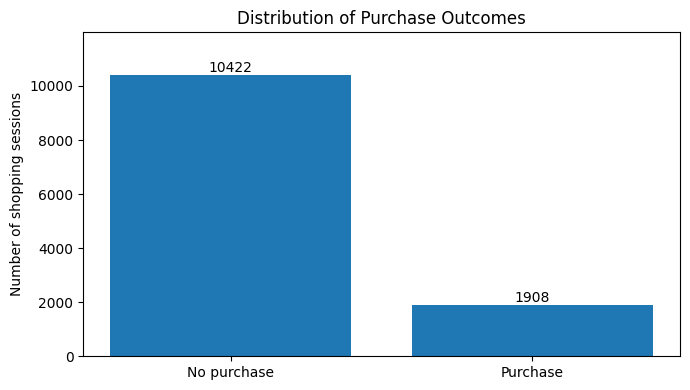

Graph saved: target_distribution.png


In [19]:
# Creating the purchase distribution graph
counts = data["Revenue"].value_counts().reindex([False, True], fill_value=0)

plt.figure(figsize=(7, 4))
bars = plt.bar(["No purchase", "Purchase"], counts.values)
plt.title("Distribution of Purchase Outcomes")
plt.ylabel("Number of shopping sessions")
plt.ylim(0, counts.max() * 1.15)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 100,
             str(int(bar.get_height())), ha="center")
plt.tight_layout()
plt.savefig("target_distribution.png", dpi=150)
plt.show()
print("Graph saved: target_distribution.png")

## 2. Feature selection (Part 2)

We predict `Revenue` ($y\in\{0,1\}$). We remove the target from the inputs, and omit `PageValues` from the **primary** model as a conservative choice about prediction-time availability. This is not proof that `PageValues` always leaks target information. Full-session features also prevent a claim that this is necessarily an *early-session* prediction model.

In [20]:
# Selecting numerical variables
numbers = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
]

# Selecting categorical variables
categories = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]

# Combining the selected variables
features = numbers + categories

# Separating inputs and target
X = data[features]
y = data["Revenue"].astype(int)

# Checking the selected variables
print("Total browsing sessions:", len(data))
print("Number of input variables:", X.shape[1])
print("Numerical variables:", len(numbers))
print("Categorical variables:", len(categories))
print()
print("Excluded variables:")
for name in data.columns:
    if name not in features:
        print(name)
print()
print("First five shopping sessions:")
display(X.head())
print("Purchases and non-purchases:")
print(y.value_counts())

assert len(features) == 16
assert set(data.columns) - set(features) == {"PageValues", "Revenue"}
print("OK - feature selection")

Total browsing sessions: 12330
Number of input variables: 16
Numerical variables: 9
Categorical variables: 7

Excluded variables:
PageValues
Revenue

First five shopping sessions:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,Feb,3,3,1,4,Returning_Visitor,True


Purchases and non-purchases:
Revenue
0    10422
1     1908
Name: count, dtype: int64
OK - feature selection


## 3. Reproducible training, validation and test split (Part 3)

We follow Lab 1: `np.random.default_rng(seed).permutation(n)` shuffles **row indices**, and `.iloc` selects the corresponding rows. We use an additional validation group. The shuffle is **not stratified**, so purchase rates differ slightly across groups.

| Group | Fraction | Rows | Role |
|:--|--:|--:|:--|
| Training | 60% | 7,398 | Learn the rules |
| Validation | 20% | 2,466 | Select tree depth |
| Test | 20% | 2,466 | Evaluate final chosen model once |

Crucially, do not shuffle `X` and `y` independently.

In [21]:
# Shuffling the row indices
n = len(data)
indices = np.random.default_rng(42).permutation(n)

# Calculating the number of rows
n_test = round(0.2 * n)
n_val = round(0.2 * n)

# Dividing the indices into three groups
test_idx = indices[:n_test]
val_idx = indices[n_test:n_test + n_val]
train_idx = indices[n_test + n_val:]

# Selecting the corresponding rows
X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

# Checking the split sizes
assert len(X_train) == 7398
assert len(X_val) == 2466
assert len(X_test) == 2466
assert len(np.unique(indices)) == n
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))

print("OK - dataset split completed")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print()
print("Purchase rates:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

OK - dataset split completed
Training: 7398
Validation: 2466
Test: 2466

Purchase rates:
Training: 15.22 %
Validation: 16.34 %
Test: 15.37 %


**Recorded split results:** Training 15.22%, validation 16.34%, test 15.37%. Identical values are expected only when the same CSV and row ordering are used.

## 4. Preprocessing — one-hot encoding (Part 4)

The scratch tree expects a numerical matrix. We use Lab 1's `pd.get_dummies()`, `.reindex()` and `.to_numpy()` rather than a complex pipeline. Categorical codes such as `Browser=2` are labels, not quantities. Each category becomes a separate 0/1 feature.

We split **before** encoding. Training data determines the output columns. Validation/test data are aligned to **training** columns, avoiding validation/test-derived feature definitions. No standardization is necessary for this threshold-based tree. The EDA shows no missing values, so no imputation is needed in this dataset.

In [22]:
# Working with copies of the datasets
train = X_train.copy()
val = X_val.copy()
test = X_test.copy()

# Converting categories to text
for column in categories:
    train[column] = train[column].astype(str)
    val[column] = val[column].astype(str)
    test[column] = test[column].astype(str)

# Converting categories into numerical columns
train_encoded = pd.get_dummies(train, columns=categories, dtype=float)
val_encoded = pd.get_dummies(val, columns=categories, dtype=float)
test_encoded = pd.get_dummies(test, columns=categories, dtype=float)

# Using the same columns as the training dataset
val_encoded = val_encoded.reindex(columns=train_encoded.columns, fill_value=0.0)
test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0.0)

# Converting the datasets into NumPy arrays
X_train_ready = train_encoded.to_numpy(dtype=float)
X_val_ready = val_encoded.to_numpy(dtype=float)
X_test_ready = test_encoded.to_numpy(dtype=float)

# Converting the outcomes into NumPy arrays
y_train = y_train.to_numpy()
y_val = y_val.to_numpy()
y_test = y_test.to_numpy()

# Checking the results
print("Training shape:", X_train_ready.shape)
print("Validation shape:", X_val_ready.shape)
print("Test shape:", X_test_ready.shape)

assert X_train_ready.shape[1] == X_val_ready.shape[1] == X_test_ready.shape[1]
assert X_train_ready.shape[0] == len(y_train)
assert X_val_ready.shape[0] == len(y_val)
assert X_test_ready.shape[0] == len(y_test)
assert np.isfinite(X_train_ready).all()
assert np.isfinite(X_val_ready).all()
assert np.isfinite(X_test_ready).all()
print("OK - preprocessing completed")

Training shape: (7398, 72)
Validation shape: (2466, 72)
Test shape: (2466, 72)
OK - preprocessing completed


**Recorded shapes:** training `(7398, 72)`; validation `(2466, 72)`; test `(2466, 72)`. The original 16 features become 72 numerical columns after one-hot encoding.

## 5. Mathematical foundations of the decision tree (Part 5)

### Gini impurity

For binary classes $0$ and $1$, with purchase proportion $p$:

$$G(y)=1-p^2-(1-p)^2.$$

A pure node has $G=0$; equal class proportions give $G=0.5$. Example: $y=[0,0,0,0,1]$, $p=1/5$, and $G=1-0.2^2-0.8^2=0.32$.

### Weighted impurity

A threshold $t$ on feature $j$ divides the data into

$$L=\{i:X_{ij}\leq t\},\qquad R=\{i:X_{ij}>t\}.$$

The split's weighted impurity is

$$G_{\mathrm{split}}=\frac{n_L}{n}G(y_L)+\frac{n_R}{n}G(y_R).$$

We choose a split with the smallest weighted impurity **only if it improves the current node**. We stop at a pure node, a maximum depth, or when no valid improving split remains. At a leaf, we predict the majority class. Our initial experiment uses `max_depth=5` and `min_samples_leaf=20`.

**Methodological detail:** To make the scratch code manageable, continuous features with many distinct values use a small grid of quantile-based thresholds, not an exhaustive best-split search. Thus it is an **approximate greedy** decision tree, unlike scikit-learn's more comprehensive and optimized threshold search.

In [27]:
# Checking the Gini functions and displaying results

print("=== Gini Impurity Tests ===")

gini_tests = [
    ([0, 0, 0, 0], 0.0),
    ([0, 0, 1, 1], 0.5),
    ([0, 0, 0, 0, 1], 0.32),
]

for y, expected in gini_tests:
    result = gini(np.array(y))
    assert np.isclose(result, expected)

    print(f"Labels: {y}")
    print(f"Calculated Gini: {result:.4f}")
    print(f"Expected Gini:   {expected:.4f}")
    print("Status: PASS\n")


print("=== Weighted Gini Impurity Tests ===")

weighted_tests = [
    ([0, 0], [1, 1], 0.0),
    ([0, 1], [0, 1], 0.5),
    ([0, 0, 1], [1], 1 / 3),
]

for left, right, expected in weighted_tests:
    result = weighted_gini(np.array(left), np.array(right))
    assert np.isclose(result, expected)

    print(f"Left labels:  {left}")
    print(f"Right labels: {right}")
    print(f"Calculated weighted Gini: {result:.4f}")
    print(f"Expected weighted Gini:   {expected:.4f}")
    print("Status: PASS\n")

=== Gini Impurity Tests ===
Labels: [0, 0, 0, 0]
Calculated Gini: 0.0000
Expected Gini:   0.0000
Status: PASS

Labels: [0, 0, 1, 1]
Calculated Gini: 0.5000
Expected Gini:   0.5000
Status: PASS

Labels: [0, 0, 0, 0, 1]
Calculated Gini: 0.3200
Expected Gini:   0.3200
Status: PASS

=== Weighted Gini Impurity Tests ===
Left labels:  [0, 0]
Right labels: [1, 1]
Calculated weighted Gini: 0.0000
Expected weighted Gini:   0.0000
Status: PASS

Left labels:  [0, 1]
Right labels: [0, 1]
Calculated weighted Gini: 0.5000
Expected weighted Gini:   0.5000
Status: PASS

Left labels:  [0, 0, 1]
Right labels: [1]
Calculated weighted Gini: 0.3333
Expected weighted Gini:   0.3333
Status: PASS



In [23]:
# Calculating Gini impurity
def gini(y):
    if len(y) == 0:
        return 0.0

    p = np.mean(y)
    return 1 - p**2 - (1 - p)**2


# Calculating weighted Gini impurity
def weighted_gini(y_left, y_right):
    n_left = len(y_left)
    n_right = len(y_right)
    n = n_left + n_right

    if n == 0:
        return 0.0

    return (n_left / n) * gini(y_left) + (n_right / n) * gini(y_right)


# Checking the Gini functions
assert np.isclose(gini(np.array([0, 0, 0, 0])), 0.0)
assert np.isclose(gini(np.array([0, 0, 1, 1])), 0.5)
assert np.isclose(gini(np.array([0, 0, 0, 0, 1])), 0.32)
assert np.isclose(weighted_gini(np.array([0, 0]), np.array([1, 1])), 0.0)
assert np.isclose(weighted_gini(np.array([0, 1]), np.array([0, 1])), 0.5)
assert np.isclose(weighted_gini(np.array([0, 0, 1]), np.array([1])), 1 / 3)
print("OK - Gini impurity")
print("OK - weighted Gini impurity")

OK - Gini impurity
OK - weighted Gini impurity


In [24]:
# Finding the best feature and threshold
def best_split(X, y, min_samples_leaf=20):
    best_feature = None
    best_threshold = None
    best_score = gini(y)

    for j in range(X.shape[1]):
        values = np.unique(X[:, j])

        if len(values) <= 1:
            continue

        if len(values) <= 16:
            thresholds = (values[:-1] + values[1:]) / 2
        else:
            thresholds = np.unique(
                np.quantile(values, np.linspace(0, 1, 17)[1:-1])
            )

        for t in thresholds:
            left = X[:, j] <= t
            right = ~left

            if left.sum() < min_samples_leaf or right.sum() < min_samples_leaf:
                continue

            score = weighted_gini(y[left], y[right])

            if score < best_score - 1e-12:
                best_score = score
                best_feature = j
                best_threshold = t

    return best_feature, best_threshold


# Building the decision tree
def build_tree(X, y, depth=0, max_depth=5, min_samples_leaf=20):
    prediction = int(np.mean(y) >= 0.5)

    if depth >= max_depth or gini(y) == 0:
        return {"prediction": prediction}

    j, t = best_split(X, y, min_samples_leaf)

    if j is None:
        return {"prediction": prediction}

    left = X[:, j] <= t
    right = ~left

    return {
        "feature": j,
        "threshold": t,
        "left": build_tree(X[left], y[left], depth + 1, max_depth, min_samples_leaf),
        "right": build_tree(X[right], y[right], depth + 1, max_depth, min_samples_leaf),
    }


# Predicting one shopping session
def predict_one(x, tree):
    if "prediction" in tree:
        return tree["prediction"]

    if x[tree["feature"]] <= tree["threshold"]:
        return predict_one(x, tree["left"])

    return predict_one(x, tree["right"])


# Predicting all shopping sessions
def predict(X, tree):
    return np.array([predict_one(x, tree) for x in X])


# Checking the split and predictions on a small dataset
X_small = np.array([[1], [2], [3], [4]], dtype=float)
y_small = np.array([0, 0, 1, 1])
j, t = best_split(X_small, y_small, min_samples_leaf=1)
assert j == 0
assert np.isclose(t, 2.5)
print("OK - best split")
small_tree = build_tree(X_small, y_small, max_depth=2, min_samples_leaf=1)
assert np.array_equal(predict(X_small, small_tree), y_small)
print("OK - tree predictions")

OK - best split
OK - tree predictions


## 6. Classification metrics

Define true positives $TP$, false positives $FP$, true negatives $TN$ and false negatives $FN$. Then

$$\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN}.$$

$$F_1=\frac{2PR}{P+R}.$$

If a denominator is zero, we report that metric as 0. Accuracy alone is misleading for our imbalanced outcome: always guessing "no purchase" is often accurate while never identifying a purchase.

In [25]:
# Calculating classification metrics
def classification_metrics(y, y_pred):
    tp = np.sum((y == 1) & (y_pred == 1))
    tn = np.sum((y == 0) & (y_pred == 0))
    fp = np.sum((y == 0) & (y_pred == 1))
    fn = np.sum((y == 1) & (y_pred == 0))

    accuracy = np.mean(y == y_pred)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0

    return {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1}


# Checking a simple example
example_y = np.array([0, 0, 1, 1])
example_pred = np.array([0, 1, 1, 0])
example_scores = classification_metrics(example_y, example_pred)
assert np.isclose(example_scores["Accuracy"], 0.5)
assert np.isclose(example_scores["Precision"], 0.5)
assert np.isclose(example_scores["Recall"], 0.5)
assert np.isclose(example_scores["F1"], 0.5)
print("OK - classification metrics")

OK - classification metrics


## 7. Initial NumPy decision tree (Part 5 validation)

First reproduce the **depth-5, minimum-leaf-20** run from Part 5. This runs only on training and validation data; it does **not** inspect the test outcome.

In [26]:
# Training our first decision tree
tree_5 = build_tree(X_train_ready, y_train, max_depth=5, min_samples_leaf=20)

# Predicting the validation dataset
pred_5 = predict(X_val_ready, tree_5)
scores_5 = classification_metrics(y_val, pred_5)
print("Validation results for our tree (depth 5):")
for name, value in scores_5.items():
    print(name + ":", round(value, 4))

# Comparing with the no-purchase baseline
baseline_val = np.zeros(len(y_val), dtype=int)
print("Baseline validation results:")
for name, value in classification_metrics(y_val, baseline_val).items():
    print(name + ":", round(value, 4))

assert len(pred_5) == 2466
print("OK - initial tree trained")

Validation results for our tree (depth 5):
Accuracy: 0.8317
Precision: 0.4375
Recall: 0.1042
F1: 0.1683
Baseline validation results:
Accuracy: 0.8366
Precision: 0.0
Recall: 0.0
F1: 0.0
OK - initial tree trained


**Previously observed output:** our depth-5 tree had Accuracy `0.8317`, Precision `0.4375`, Recall `0.1042`, F1 `0.1683`. The validation majority-class baseline had Accuracy `0.8366`, with zero precision/recall/F1.

## 8. Compare NumPy with scikit-learn (Part 6)

Following Lab 1's compare-with-scikit-learn section, we fit both models to the **same 7,398 training observations**, then compute metrics on the **same 2,466 validation observations**. We compare depths $3,5,7$, keeping `min_samples_leaf=20` and the Gini criterion. We choose by **validation F1**, not by test performance.

Both trees are valid models with distinct split-search implementations; different predictions are expected.

In [11]:
from sklearn.tree import DecisionTreeClassifier

# Comparing the tree depths
results = []
for depth in [3, 5, 7]:

    # Training our decision tree
    tree = build_tree(X_train_ready, y_train, max_depth=depth, min_samples_leaf=20)
    y_pred = predict(X_val_ready, tree)
    scores = classification_metrics(y_val, y_pred)
    results.append({"Model": "Our tree", "Depth": depth, **scores})

    # Training the scikit-learn decision tree
    sklearn_tree = DecisionTreeClassifier(
        criterion="gini", max_depth=depth, min_samples_leaf=20, random_state=42
    )
    sklearn_tree.fit(X_train_ready, y_train)
    y_pred = sklearn_tree.predict(X_val_ready)
    scores = classification_metrics(y_val, y_pred)
    results.append({"Model": "Scikit-learn", "Depth": depth, **scores})

# Displaying validation results
comparison = pd.DataFrame(results)
print("Validation results:")
print(comparison.round(4).to_string(index=False))

# Selecting the best model using validation F1
best = comparison.loc[comparison["F1"].idxmax()]
print()
print("Best model:", best["Model"])
print("Best depth:", int(best["Depth"]))
print("Best F1-score:", round(best["F1"], 4))

# Checking the comparison
assert len(comparison) == 6
assert comparison["F1"].between(0, 1).all()
print("OK - model comparison completed")

Validation results:
       Model  Depth  Accuracy  Precision  Recall     F1
    Our tree      3    0.8366     0.0000  0.0000 0.0000
Scikit-learn      3    0.8366     0.0000  0.0000 0.0000
    Our tree      5    0.8317     0.4375  0.1042 0.1683
Scikit-learn      5    0.8268     0.3235  0.0546 0.0934
    Our tree      7    0.8297     0.4190  0.1092 0.1732
Scikit-learn      7    0.8297     0.3768  0.0645 0.1102

Best model: Our tree
Best depth: 7
Best F1-score: 0.1732
OK - model comparison completed


### Recorded validation results from VS Code

| Model | Depth | Accuracy | Precision | Recall | F1 |
|:--|--:|--:|--:|--:|--:|
| Our tree | 3 | 0.8366 | 0.0000 | 0.0000 | 0.0000 |
| Scikit-learn | 3 | 0.8366 | 0.0000 | 0.0000 | 0.0000 |
| Our tree | 5 | 0.8317 | 0.4375 | 0.1042 | 0.1683 |
| Scikit-learn | 5 | 0.8268 | 0.3235 | 0.0546 | 0.0934 |
| **Our tree** | **7** | **0.8297** | **0.4190** | **0.1092** | **0.1732** |
| Scikit-learn | 7 | 0.8297 | 0.3768 | 0.0645 | 0.1102 |

Our highest measured validation F1 was **0.1732** with **depth 7**, minimum leaf 20. These numbers are historical outputs from the work in this chat, not new results manufactured by this notebook.

## 9. Model comparison visualization (Part 8)

Generate the figure **from the computed results**, rather than manually typing scores into the plotting cell. This is better for reproducibility and will match the graph generated in your local project when the measured scores match.

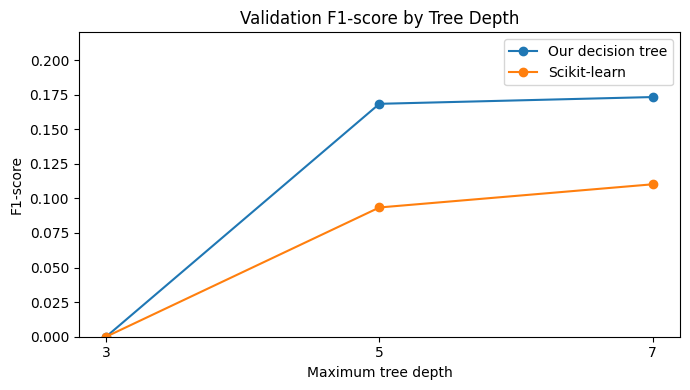

Graph saved: model_comparison.png


In [12]:
# Getting the F1-scores from the comparison
our_results = comparison[comparison["Model"] == "Our tree"]
sklearn_results = comparison[comparison["Model"] == "Scikit-learn"]

# Creating the graph
plt.figure(figsize=(7, 4))
plt.plot(our_results["Depth"], our_results["F1"], "o-", label="Our decision tree")
plt.plot(sklearn_results["Depth"], sklearn_results["F1"], "o-", label="Scikit-learn")

# Adding labels and a title
plt.xlabel("Maximum tree depth")
plt.ylabel("F1-score")
plt.title("Validation F1-score by Tree Depth")
plt.xticks([3, 5, 7])
plt.ylim(0, 0.22)
plt.legend()

# Saving and displaying the graph
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()
print("Graph saved: model_comparison.png")

## 10. Final independent test (Part 7)

**The decision was made using validation results only:** use our NumPy tree with `max_depth=7` and `min_samples_leaf=20`. This cell trains the selected configuration on the **same original training partition** and evaluates on the untouched test group, following the project's original experiment. Do not retune after seeing the test results.

For statistical rigor, this is a **single random holdout**. It should not be interpreted as proof of robustness to future traffic patterns or deployment conditions.

In [13]:
# Training the selected decision tree
tree_final = build_tree(
    X_train_ready, y_train, max_depth=7, min_samples_leaf=20
)

# Predicting the independent test dataset
y_pred_test = predict(X_test_ready, tree_final)
test_scores = classification_metrics(y_test, y_pred_test)

# Displaying the final test results
print("Final test results:")
for name, value in test_scores.items():
    print(name + ":", round(value, 4))

# Comparing with the baseline
baseline_test = np.zeros(len(y_test), dtype=int)
baseline_scores = classification_metrics(y_test, baseline_test)
print()
print("Baseline test results:")
for name, value in baseline_scores.items():
    print(name + ":", round(value, 4))

# Checking final predictions
assert len(y_pred_test) == len(y_test)
assert set(np.unique(y_pred_test)).issubset({0, 1})
print("OK - final test completed")

Final test results:
Accuracy: 0.8382
Precision: 0.4
Recall: 0.1055
F1: 0.167

Baseline test results:
Accuracy: 0.8463
Precision: 0.0
Recall: 0.0
F1: 0.0
OK - final test completed


### Previously recorded final test results

| Metric | Scratch tree, depth 7 | Always predict 0 |
|:--|--:|--:|
| Accuracy | **0.8382** | **0.8463** |
| Precision | **0.4000** | **0.0000** |
| Recall | **0.1055** | **0.0000** |
| F1-score | **0.1670** | **0.0000** |

These were observed in your VS Code output. The notebook above **recomputes** them from the uploaded data; it never overwrites the new scores to force a match.

**Interpretation:** A majority-class predictor can exceed our model's accuracy because purchases are rare, yet fail to identify any purchases. Our model identifies some purchasers, but its roughly 10.55% recall shows that it misses most of them.

## 11. Final comparison table, confusion matrix and exports

In [14]:
# Creating a table of the final test results
final_table = pd.DataFrame([
    {"Model": "Our NumPy tree", **test_scores},
    {"Model": "Always no purchase", **baseline_scores},
])
display(final_table.round(4))

# Counting the final test outcomes
tp = int(np.sum((y_test == 1) & (y_pred_test == 1)))
tn = int(np.sum((y_test == 0) & (y_pred_test == 0)))
fp = int(np.sum((y_test == 0) & (y_pred_test == 1)))
fn = int(np.sum((y_test == 1) & (y_pred_test == 0)))

# Displaying the confusion matrix
matrix = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual no purchase", "Actual purchase"],
    columns=["Predicted no purchase", "Predicted purchase"],
)
print("Final test confusion matrix:")
display(matrix)
assert tp + tn + fp + fn == len(y_test)

# Saving the results
comparison.to_csv("validation_model_comparison.csv", index=False)
final_table.to_csv("final_test_metrics.csv", index=False)
matrix.to_csv("final_test_confusion_matrix.csv")
print("OK - result tables saved")

,Model,Accuracy,Precision,Recall,F1
0,Our NumPy tree,0.8382,0.4,0.1055,0.167
1,Always no purchase,0.8463,0.0,0.0000,0.000


Final test confusion matrix:


,Predicted no purchase,Predicted purchase
Actual no purchase,2027,60
Actual purchase,339,40


OK - result tables saved


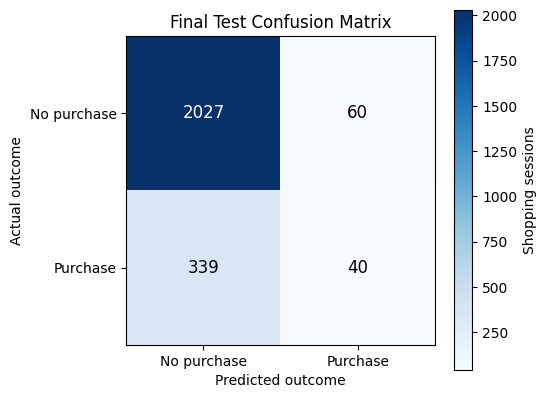

Graph saved: final_test_confusion_matrix.png


In [15]:
# Plotting the final test confusion matrix
plt.figure(figsize=(5.5, 4.5))
plt.imshow([[tn, fp], [fn, tp]], cmap="Blues")
plt.xticks([0, 1], ["No purchase", "Purchase"])
plt.yticks([0, 1], ["No purchase", "Purchase"])
plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.title("Final Test Confusion Matrix")

# Adding the exact counts to the figure
for i, row in enumerate([[tn, fp], [fn, tp]]):
    for j, value in enumerate(row):
        plt.text(j, i, str(value), ha="center", va="center", fontsize=12,
                 color="white" if value > max(tn, fp, fn, tp) / 2 else "black")
plt.colorbar(label="Shopping sessions")
plt.tight_layout()
plt.savefig("final_test_confusion_matrix.png", dpi=150)
plt.show()
print("Graph saved: final_test_confusion_matrix.png")

## 12. Scientific interpretation and limitations

### Main conclusions

1. The outcome is imbalanced: about **84.53%** of all sessions do not end in a purchase. As a result, accuracy alone is inadequate.
2. Our NumPy-based Gini tree was implemented from scratch and verified with simple checkpoints. It identifies some purchases but has **low recall**.
3. Under the **three depths tested** with minimum leaf size 20, the scratch tree obtained a higher validation F1 than scikit-learn. This does **not** imply that it is generally a superior algorithm: threshold candidates differ and hyperparameter search was limited.
4. The validation-best tree was evaluated once on the held-out test partition. It achieved the previously observed **0.1670 F1**, compared with 0 for a no-purchase baseline.

### Important limitations to discuss in your report

- **Threshold search:** The custom algorithm tests restricted thresholds on high-cardinality features; it is not an exhaustive CART implementation.
- **Class imbalance:** A default majority-vote threshold causes many purchase sessions to be missed.
- **Data leakage and timing:** `PageValues` was omitted from the primary model; however, other whole-session features may not be available early enough for real-time predictions.
- **Duplicate rows:** 125 exact repeated records were not removed. A random row-wise split could put identical feature patterns in different groups; a future experiment could investigate grouping or duplicate handling.
- **Random split:** This split is not stratified or chronological. It does not directly test future-period generalization.
- **Hyperparameters:** The project selected from depths 3, 5 and 7 using one minimum leaf size. More settings, imbalance-aware methods, or repeated cross-validation could be studied separately, but **do not change the already reported final-test experiment**.
- **Statistical uncertainty:** This is one holdout experiment with no confidence intervals; differences are not necessarily statistically significant.

### Mathematical method summary

The tree recursively partitions training observations based on a feature $j$ and threshold $t$ that decrease weighted Gini impurity, subject to maximum depth and minimum leaf size. Leaves predict the training majority class. It is a supervised, greedy, nonlinear classifier.

## 13. Reproducibility checklist

- [x] Keep `Revenue` out of input features.
- [x] Exclude `PageValues` from the primary analysis.
- [x] Use the *same* source CSV, row ordering and random seed 42.
- [x] Split data before categorical encoding.
- [x] Determine one-hot columns from **training data only**.
- [x] Train scratch tree with NumPy and compare with scikit-learn using the same split.
- [x] Tune tree depth on **validation F1**, not test F1.
- [x] Evaluate selected configuration on the held-out test dataset.
- [x] Report the baseline and limitations honestly.

### Original repository structure

`src/eda.py`, `src/features.py`, `src/split_data.py`, `src/preprocessing.py`, `src/tree_scratch.py`, `src/run_project.py`, `src/final_test.py`, `src/visualize_results.py`; figures under `results/`.

**Repository:** https://github.com/charlottedelphinar/maths-stats-ml-project-22102026-cdr

**Class reference:** *Lab1_Regression_from_scratch_STUDENT.ipynb* — NumPy permutation, pandas encoding and alignment, scratch metrics, checkpoints, and comparisons with scikit-learn. The decision-tree formulas themselves belong to the decision-tree topic, not to the regression algorithm taught in Lab 1.

**Download results:** Use Colab's left Files pane to download saved `.png` and `.csv` outputs after running all cells.

## 14. Checking the numbers against your original VS Code results

This final checkpoint **compares** the freshly computed results with the exact rounded numbers you shared. It does not change predictions or force a match. If a comparison differs, verify the uploaded CSV, row order, library versions, and code before interpreting the discrepancy.

In [16]:
# Getting the reference results recorded during the original project
expected_split_rates = [15.22, 16.34, 15.37]
actual_split_rates = [round(np.mean(v) * 100, 2) for v in [y_train, y_val, y_test]]

expected_validation_f1 = [0.0000, 0.0000, 0.1683, 0.0934, 0.1732, 0.1102]
actual_validation_f1 = comparison["F1"].round(4).tolist()

expected_test = {"Accuracy": 0.8382, "Precision": 0.4000, "Recall": 0.1055, "F1": 0.1670}

# Comparing calculated results with the recorded values
print("Split purchase rates match:", actual_split_rates == expected_split_rates)
print("Validation F1-scores match:", actual_validation_f1 == expected_validation_f1)
print("Final test metrics:")
for name, expected in expected_test.items():
    actual = round(test_scores[name], 4)
    print(name + ":", actual, "| expected:", expected, "| match:", actual == expected)

print("OK - reference comparison completed (see match indicators above)")

Split purchase rates match: True
Validation F1-scores match: True
Final test metrics:
Accuracy: 0.8382 | expected: 0.8382 | match: True
Precision: 0.4 | expected: 0.4 | match: True
Recall: 0.1055 | expected: 0.1055 | match: True
F1: 0.167 | expected: 0.167 | match: True
OK - reference comparison completed (see match indicators above)
